# Does combined keep descending, and does a bigger lr help?

Reproduced cell: `opt-adam_b-256_init-normal__combined_seed1_x_0.4`, 500 epochs, NO early
stopping, lr swept over [0.02, 0.03, 0.04]. This notebook loads the per-lr metrics json
(full train/test history incl. epoch 0 = random init) that `train_increasing_epochs_for_combined.py`
wrote next to itself, and plots the loss curves. The saved `.pth` checkpoints (best-train) are
also loadable here if needed.


In [5]:
import glob, json, os
import numpy as np
import matplotlib.pyplot as plt

HERE = os.getcwd()
metrics = {}
for mp in sorted(glob.glob(os.path.join(HERE, 'metrics_combined_seed1_x_0.4_lr-*.json'))):
    m = json.load(open(mp))
    metrics[m['lr']] = m
lrs = sorted(metrics, reverse=True)
print('loaded lrs:', lrs)
for lr in lrs:
    m = metrics[lr]
    print(f"  lr={lr}: epochs_run={m['epochs_run']}  best_train={m['best_train']:.4f}  "
          f"test_at_best={m['test_at_best']:.4f}  final_train={m['final_train']:.4f}  "
          f"final_test={m['final_test']:.4f}")


loaded lrs: [0.04, 0.03, 0.02]
  lr=0.04: epochs_run=500  best_train=1.7795  test_at_best=1.7910  final_train=1.7800  final_test=1.7947
  lr=0.03: epochs_run=500  best_train=1.7751  test_at_best=1.7904  final_train=1.7755  final_test=1.7922
  lr=0.02: epochs_run=500  best_train=1.7855  test_at_best=1.8069  final_train=1.7855  final_test=1.8069


## Train & test loss vs epoch, all lrs

Left = train CE, right = test CE. Epoch 0 is the shared random init (same for every lr).
The horizontal dashed line marks folder 13's separate-arch result for this cell, if you
paste it into `SEP_REF` -- so you can see how close raising combined's lr gets to it.


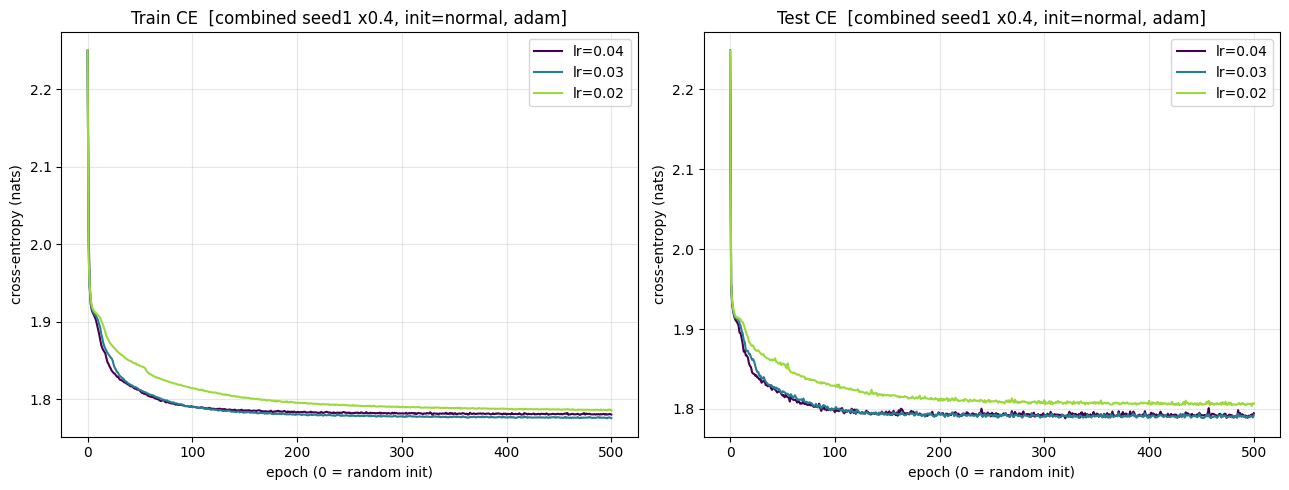

saved -> loss_curves_lr_sweep.png


In [ ]:
SEP_REF = None   # e.g. 0.90 -- separate's test_at_best for this cell, for a reference line

colors = plt.cm.viridis(np.linspace(0, 0.85, len(lrs)))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for lr, c in zip(lrs, colors):
    h = metrics[lr]['history']
    ep = np.arange(len(h['train_loss']))
    axes[0].plot(ep, h['train_loss'], color=c, label=f'lr={lr}')
    axes[1].plot(ep, h['test_loss'],  color=c, label=f'lr={lr}')
for ax, ttl, key in [(axes[0], 'Train CE', 'train_loss'), (axes[1], 'Test CE', 'test_loss')]:
    if SEP_REF is not None:
        ax.axhline(SEP_REF, color='tab:orange', ls='--', lw=1, label='separate ref')
    ax.set_title(f'{ttl}  [combined seed1 x0.4, init=normal, adam]')
    ax.set_xlabel('epoch (0 = random init)'); ax.set_ylabel('cross-entropy (nats)')
    ax.grid(alpha=0.3); ax.legend()
fig.tight_layout()
fig.savefig('loss_curves_lr_sweep.png', dpi=140)
plt.show()
print('saved -> loss_curves_lr_sweep.png')


## Zoom: is it still descending at the end?

Train CE over the LAST 100 epochs only -- a flat tail means it converged; a still-sloping
tail means the budget (or lr) was the limiter, which is exactly the question that prompted
this run.


lr=0.04: last-20-epoch avg train slope = -1.26e-05 nats/epoch (still descending)
lr=0.03: last-20-epoch avg train slope = -2.40e-05 nats/epoch (still descending)
lr=0.02: last-20-epoch avg train slope = -2.97e-05 nats/epoch (still descending)


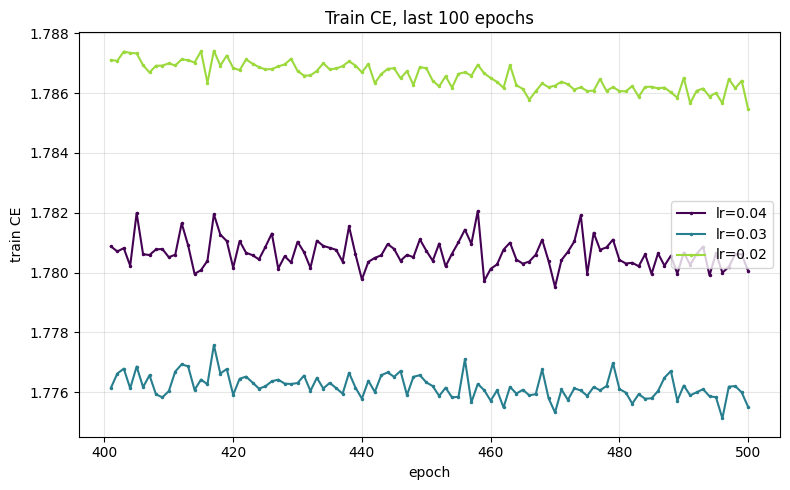

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
for lr, c in zip(lrs, colors):
    h = metrics[lr]['history']['train_loss']
    n = len(h); start = max(0, n - 100)
    ax.plot(range(start, n), h[start:], color=c, marker='.', ms=3, label=f'lr={lr}')
    slope = (h[-1] - h[-min(20, n)]) / min(20, n)   # avg per-epoch change over last ~20 ep
    print(f'lr={lr}: last-20-epoch avg train slope = {slope:+.2e} nats/epoch '
          f'({"still descending" if slope < -1e-5 else "flat/converged"})')
ax.set_title('Train CE, last 100 epochs'); ax.set_xlabel('epoch'); ax.set_ylabel('train CE')
ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); plt.show()


## (optional) Load a checkpoint

Rebuild the model and load any lr's best-train weights -- e.g. to inspect attention or run
further diagnostics. Imports the model straight from the training script (same directory).


In [8]:
import importlib.util, torch
spec = importlib.util.spec_from_file_location(
    'trinc', os.path.join(HERE, 'train_increasing_epochs_for_combined.py'))
trinc = importlib.util.module_from_spec(spec); spec.loader.exec_module(trinc)

C = trinc.CONFIG; V = C['v_sig'] + C['n_noise']; attn_dim = V + C['seq_len']
def load_ckpt(lr, device='cpu'):
    m = trinc.SimplifiedTransformerMLP(V, C['seq_len'], attn_dim, C['v_sig'],
                                       C['freeze_hidden_k'], bias=C['bias'],
                                       attn_param=C['attn_param']).to(device)
    sd = torch.load(os.path.join(HERE, f'model_combined_seed1_x_0.4_lr-{lr}.pth'),
                    map_location=device, weights_only=True)
    m.load_state_dict(sd); m.eval(); return m
print('load_ckpt(lr) ready for lrs:', lrs)


load_ckpt(lr) ready for lrs: [0.04, 0.03, 0.02]
